# 3. Metodología de análisis de datos con IA

## Algortimos de aprendizaje clásico: Random Forest (RF)

In [1]:
# Importar librerías
import pandas as pd
# Importar Random Forest, en scikit-learn se llama Support Vector Classifier (SVC)
from sklearn.ensemble import RandomForestClassifier
# Importar objeto para k-fold cross-validation con grid de hyperparámetros
from sklearn.model_selection import GridSearchCV
# Importar objeto para separación de datos en conjuntos de entrenamiento y evaluación
from sklearn.model_selection import train_test_split
# Importar objeto para escalamiento de datos
from sklearn.preprocessing import StandardScaler
# Importar metricas de evaluación
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score, roc_curve
# Importar objeto para imprimir matriz de confusión
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# Importar objeto para imprimir reporte de clasificación
from sklearn.metrics import classification_report
# Plots
import matplotlib.pyplot as plt


## 1. Leer conjunto de datos
Origen y descripción de conjunto de datos en:
https://archive.ics.uci.edu/ml/datasets/Heart+failure+clinical+records

In [2]:
data_set = pd.read_csv("/mnt/c/Users/vrahu/Documents/Ismadlsh/CCG/2026-S5/Data_Science/data/heart_failure_clinical_records_dataset.csv")
data_set.head(6)

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1
5,90.0,1,47,0,40,1,204000.00,2.1,132,1,1,8,1


### Verificar dimensionalidad de datos

In [3]:
print("Dimensionalidad del data set")
data_set.shape

Dimensionalidad del data set


(299, 13)

### Verificar categorías de clase

In [4]:
print("Categorías únicas de clasificación")
data_set['DEATH_EVENT'].unique()

Categorías únicas de clasificación


array([1, 0])

### Verificar cuántos ejemplos hay por categoría, verificar si existe desbalance de datos

In [5]:
print("Ejemplos por categoría")
print(data_set.groupby('DEATH_EVENT').size())

Ejemplos por categoría
DEATH_EVENT
0    203
1     96
dtype: int64


## 2. Preparación de datos
### 2.1 Separación de características y categorías de clase

*   Guardar en X sólo características
*   Guardar en y sólo categorías de clase


Guardar

In [6]:
X = data_set.iloc[:,0:11]  # todos los renglones y las columnas de la 0 a la 11
print("Características")
print(X.head())

Características
    age  anaemia  creatinine_phosphokinase  diabetes  ejection_fraction  \
0  75.0        0                       582         0                 20   
1  55.0        0                      7861         0                 38   
2  65.0        0                       146         0                 20   
3  50.0        1                       111         0                 20   
4  65.0        1                       160         1                 20   

   high_blood_pressure  platelets  serum_creatinine  serum_sodium  sex  \
0                    1  265000.00               1.9           130    1   
1                    0  263358.03               1.1           136    1   
2                    0  162000.00               1.3           129    1   
3                    0  210000.00               1.9           137    1   
4                    0  327000.00               2.7           116    0   

   smoking  
0        0  
1        0  
2        1  
3        0  
4        0  


In [7]:
y = data_set.iloc[:, 12]  # todos los renglones y sólo la columna 12
print("Categorias de clase")
print(y.head())

Categorias de clase
0    1
1    1
2    1
3    1
4    1
Name: DEATH_EVENT, dtype: int64


In [8]:
value_counts = y.value_counts()
print(value_counts)

DEATH_EVENT
0    203
1     96
Name: count, dtype: int64


### 2.2 Escalamiento de características

*   Guardamos en X las características escaladas



In [9]:
scaler = StandardScaler()
scaler.fit(X)
X = scaler.transform(X)
print("Características escaladas")
print(X)

Características escaladas
[[ 1.19294523e+00 -8.71104775e-01  1.65728387e-04 ... -1.50403612e+00
   7.35688190e-01 -6.87681906e-01]
 [-4.91279276e-01 -8.71104775e-01  7.51463953e+00 ... -1.41976151e-01
   7.35688190e-01 -6.87681906e-01]
 [ 3.50832977e-01 -8.71104775e-01 -4.49938761e-01 ... -1.73104612e+00
   7.35688190e-01  1.45416070e+00]
 ...
 [-1.33339153e+00 -8.71104775e-01  1.52597865e+00 ...  3.12043840e-01
  -1.35927151e+00 -6.87681906e-01]
 [-1.33339153e+00 -8.71104775e-01  1.89039811e+00 ...  7.66063830e-01
   7.35688190e-01  1.45416070e+00]
 [-9.12335403e-01 -8.71104775e-01 -3.98321274e-01 ... -1.41976151e-01
   7.35688190e-01  1.45416070e+00]]


### 2.3 Separación de datos en conjuntos de entrenamiento (tran) y prueba (test)
* Usamos función train_test_split()

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)


* Exploramos conjunto de datos de entrenamiento y categorías

In [11]:
print("Dimensionalidad de datos de entrenamiento")
print(X_train.shape)
print("Dimensionalidad de categorías de entrenamiento")
print(y_train.shape)
print("Ejemplos de entrenamiento por categoría")
print(y_train.value_counts())


Dimensionalidad de datos de entrenamiento
(239, 11)
Dimensionalidad de categorías de entrenamiento
(239,)
Ejemplos de entrenamiento por categoría
DEATH_EVENT
0    162
1     77
Name: count, dtype: int64


* Exploramos conjunto de datos de prueba y categorías

In [12]:
print("Dimensionalidad de datos de prueba")
print(X_test.shape)
print("Dimensionalidad de categorías de prueba")
print(y_test.shape)
print("Ejemplos de prueba por categoría")
print(y_test.value_counts())

Dimensionalidad de datos de prueba
(60, 11)
Dimensionalidad de categorías de prueba
(60,)
Ejemplos de prueba por categoría
DEATH_EVENT
0    41
1    19
Name: count, dtype: int64


## 3. Creación del modelo

### 3.1 Creación de objeto usando algortimo SVM (en scikit learn se llama SVC)

In [13]:
algoritmo_rf = RandomForestClassifier()

3.2 Definición de grid de hiperparámetros

In [14]:
hiperparameters = {'class_weight':['balanced', None], 'n_estimators':[100, 200, 300], 'criterion': ['gini', 'entropy']}

In [15]:
rf_model = GridSearchCV(algoritmo_rf, hiperparameters, verbose=2, scoring="f1_macro", cv=5)

In [16]:
rf_model.fit(X_train, y_train)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
[CV] END class_weight=balanced, criterion=gini, n_estimators=100; total time=   0.1s
[CV] END class_weight=balanced, criterion=gini, n_estimators=100; total time=   0.1s
[CV] END class_weight=balanced, criterion=gini, n_estimators=100; total time=   0.1s
[CV] END class_weight=balanced, criterion=gini, n_estimators=100; total time=   0.1s
[CV] END class_weight=balanced, criterion=gini, n_estimators=100; total time=   0.1s
[CV] END class_weight=balanced, criterion=gini, n_estimators=200; total time=   0.2s
[CV] END class_weight=balanced, criterion=gini, n_estimators=200; total time=   0.3s
[CV] END class_weight=balanced, criterion=gini, n_estimators=200; total time=   0.2s
[CV] END class_weight=balanced, criterion=gini, n_estimators=200; total time=   0.2s
[CV] END class_weight=balanced, criterion=gini, n_estimators=200; total time=   0.2s
[CV] END class_weight=balanced, criterion=gini, n_estimators=300; total time=   0.4s
[CV]

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'class_weight': ['balanced', None], 'criterion': ['gini', 'entropy'], 'n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection

### 3.4 Obtenemos mejor métrica y mejores hiperparámetros del mejor modelo

In [17]:
print("Mejor F-1 macro score")
print(rf_model.best_score_)
print("Mejores hyperparámetros")
print(rf_model.best_params_)

Mejor F-1 macro score
0.6965964599632762
Mejores hyperparámetros
{'class_weight': 'balanced', 'criterion': 'gini', 'n_estimators': 100}


## 4. Prueba del modelo (evaluación)
### 4.1 Predicción con datos de prueba y obtención de métricas
* La variable y_pred guardará las predicciones del modelo

In [ ]:
y_pred = rf_model.predict(X_test)
print("Resultados en la fase de prueba")
print("F-1 score: {}".format(f1_score(y_test, y_pred))) #parametro average para modificar el f1 score macro o weighted
print("Precision: {}".format(precision_score(y_test, y_pred)))
print("Recall: {}".format(recall_score(y_test, y_pred)))
print("AUROC: {}".format(roc_auc_score(y_test, y_pred)))

Resultados en la fase de prueba
F-1 score: 0.6
Precision: 0.5714285714285714
Recall: 0.631578947368421
AUROC: 0.7060333761232349


### 4.2 Matriz de confusión

In [23]:
rf_confusion_matrix=confusion_matrix(y_test, y_pred)
print(rf_confusion_matrix)

[[32  9]
 [ 7 12]]


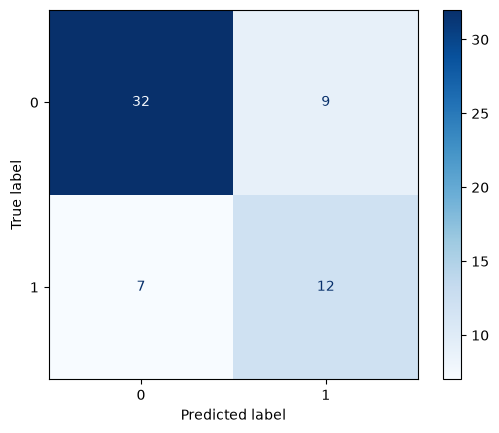

In [20]:
disp = ConfusionMatrixDisplay(confusion_matrix=rf_confusion_matrix,
                               display_labels=rf_model.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.show()

### Matriz de confusión - versión normalizada

In [25]:
rf_confusion_matrix=confusion_matrix(y_test,y_pred, normalize='true')
print(rf_confusion_matrix)

[[0.7804878  0.2195122 ]
 [0.36842105 0.63157895]]


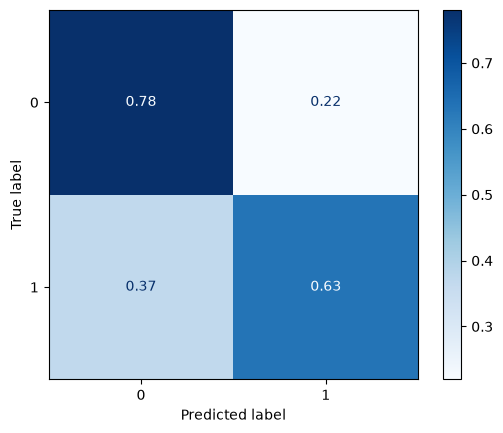

In [26]:
disp = ConfusionMatrixDisplay(confusion_matrix=rf_confusion_matrix,
                               display_labels=rf_model.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.show()

### 4.3 Reporte de clasificación

In [27]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.82      0.78      0.80        41
           1       0.57      0.63      0.60        19

    accuracy                           0.73        60
   macro avg       0.70      0.71      0.70        60
weighted avg       0.74      0.73      0.74        60



### 4.4 Curva ROC

Text(0.5, 0, 'False Positive Rate')

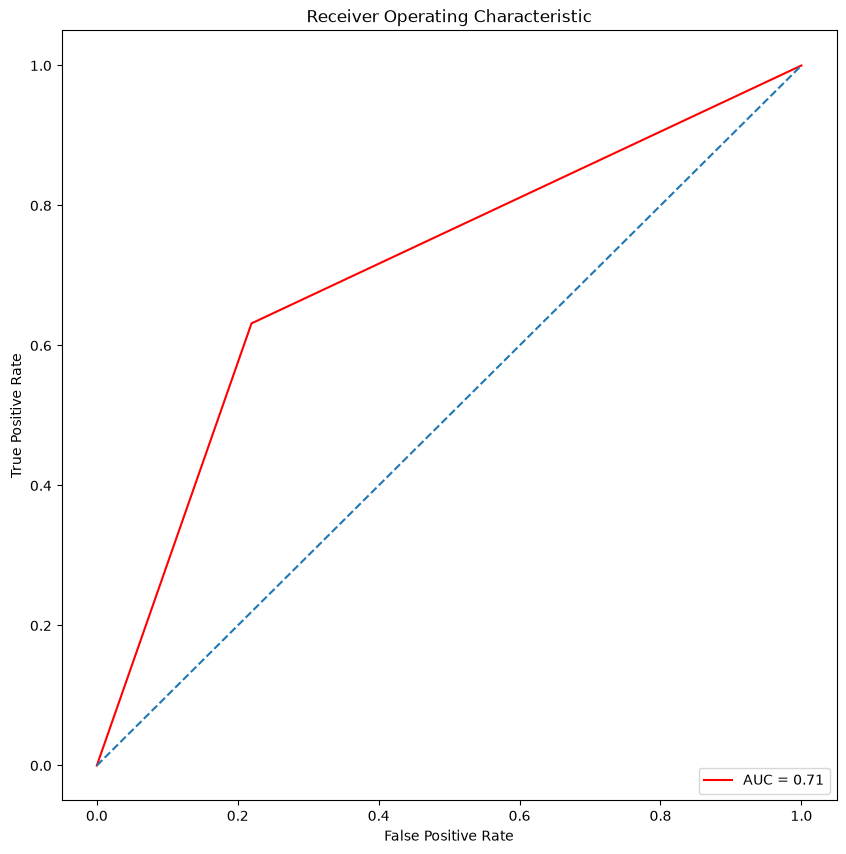

In [28]:
false_positive_rate, true_positive_rate, thresholds = roc_curve(y_test, y_pred)
auc_roc = roc_auc_score(y_test, y_pred, average='weighted')
plt.figure(figsize=(10,10))
plt.title('Receiver Operating Characteristic')
plt.plot(false_positive_rate,true_positive_rate, color='red',label = 'AUC = %0.2f' % auc_roc)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],linestyle='--')
plt.axis('tight')
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')